# Lab: CV w/CNNs

# Part 1: Libraries & Preprocessing

### Step 1: Libraries

Bring in the germane libraries.

In [20]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# TensorFlow / Keras functions
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential, Input, Model
from tensorflow.keras.layers import Dense, Conv2D, Flatten, MaxPooling2D, Dropout
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

### Step 2: Data

Download and fetch the data with the following Python code (Note: We will use faces.images for X.)

In [2]:
# Load the data
from sklearn.datasets import fetch_olivetti_faces
faces = fetch_olivetti_faces()
X = faces.images
y = faces.target.reshape(-1, 1)

### Step 3: Sample Image

Select an image from this dataset and display it (Hint: Use the plt.cm.gray color map with plt.imshow function).

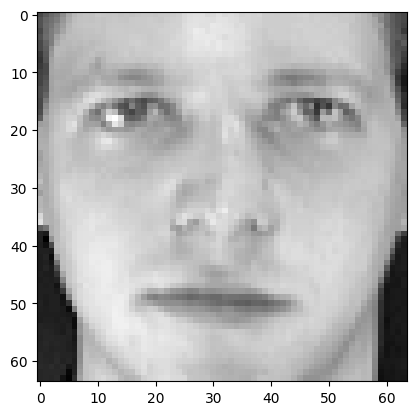

In [3]:
# Selecting an image

plt.imshow( X[0] , cmap=plt.cm.gray)


### Step 4: Training and testing sets

Setup training and testing sets . Use a 50/50 split for each class (5 training images and 5 test images per person). Print the dimension of each of the feature (image) matrices. Because this is a small dataset, we will also use the test set for validation.

In [4]:
# Creating the training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5,  stratify=y) 
print( X_train.shape)
print( X_test.shape)

(200, 64, 64)
(200, 64, 64)


### Step 5: Vector conversion

Convert the vector of response variables to a matrix with 40 columns, with indicators for which person it is (one-hot encoded vectors). Print the dimensions of the new response vectors.

In [5]:
# Conversion
y_train = to_categorical(y_train) 
y_test = to_categorical(y_test)

y_train.shape, y_test.shape 

((200, 40), (200, 40))

### Step 6: Reshape arrays

Reshape the image arrays so that they have 4 dimensions: (number of images, width of image, height of image, number of channels). For example, the array of training images should be (200, 64, 64, 1). Print the dimensions of the new image arrays.

In [6]:
# Reshape
X_test = X_test.reshape(200, 64, 64, 1)
X_train = X_train.reshape(200, 64, 64, 1)
X_test.shape, X_train.shape

((200, 64, 64, 1), (200, 64, 64, 1))

## Part 2: Model 1

### Step 7: Model 1's Architecture

Fit a convolutional neural network using the following architecture, and print the output from training.
*   1 convolutional layer with:
  * 16 filters (neurons)
  * a window size of 3
  * stride size of 1
  * ReLU activation function
  * padding so that the feature is the same size as the original image
*   1 max pooling layer with:
  * window size of 2
  * stride size of 2
  * no padding
*   1 fully connected output layer with:
  * 40 nodes for each face to predict
  * softmax activation function
*   For training, use the Adam optimizer, 20 epochs, a batch size of 10, and the categorical cross entropy loss function.

In [7]:
input_tensor = Input(shape=(64, 64, 1))

# Convolution Neural Network Model
model1 = Sequential()
model1.add(Conv2D( 16, kernel_size=3, activation='relu', 
                padding='same', input_shape=(64, 64, 1) ))
model1.add(MaxPooling2D(pool_size=(2,2), strides=2))
model1.add(Flatten())
model1.add(Dense(40, activation='softmax'))

/usr/local/Caskroom/miniconda/base/envs/learn-env/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
# Compiling model1
model1.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model1.fit(X_train, y_train, epochs=20, batch_size=10,
validation_data=(X_test, y_test))

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.0050 - loss: 5.1443 - val_accuracy: 0.0500 - val_loss: 4.2913
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.0500 - loss: 3.8942 - val_accuracy: 0.2100 - val_loss: 3.4427
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3000 - loss: 3.3558 - val_accuracy: 0.4450 - val_loss: 3.1273
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4250 - loss: 2.8461 - val_accuracy: 0.5050 - val_loss: 2.7378
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6500 - loss: 2.3045 - val_accuracy: 0.5800 - val_loss: 2.3627
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7500 - loss: 1.7715 - val_accuracy: 0.6800 - val_loss: 1.8887
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8550 - loss: 1.1827 - val_accuracy: 0.7050 - val_loss: 1.6114
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9400 - loss: 0.7527 - val_accuracy: 0.7850 - v

### Step 8: Model 1's loss and accuracy

Print the loss and accuracy on the test set.

In [9]:
# Loss and Accuracy
model1.evaluate(X_test, y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9200 - loss: 0.3810  


[0.3810405731201172, 0.9200000166893005]

### Step 9: Print image

Pick one of the images from the test set, and print the image.

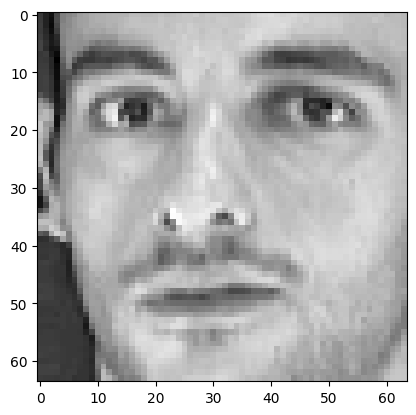

In [10]:
# An image
img_index = 0
example = X_test[img_index, :, :, 0]

plt.imshow(example, plt.cm.gray)

### Step 10: Feature maps

For the image you selected in (9), print the images of the feature maps from both the convolutional and pooling layers.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
(1, 64, 64, 16)
(1, 32, 32, 16)


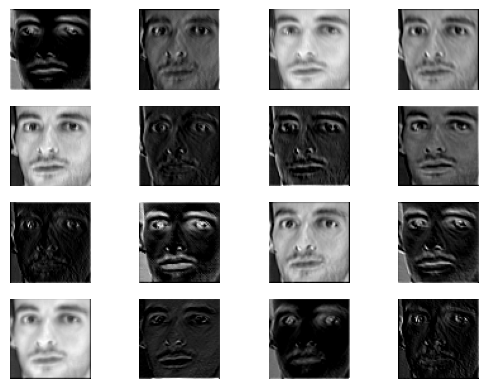

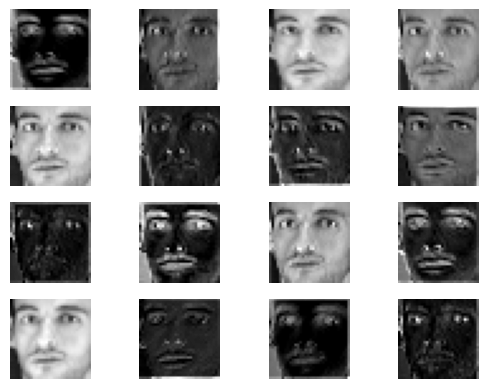

In [12]:
# Feature maps
layer_outputs = [layer.output for layer in model1.layers]
layers_model = keras.Model(inputs=model1.layers[0].input, outputs=layer_outputs )

one_image = X_test[img_index:img_index+1]
outputs = layers_model.predict(one_image)

conv_output = outputs[0]
pooling_output = outputs[1]
print(conv_output.shape)
print(pooling_output.shape)

# For loop
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(conv_output[0, :, :, i], cmap=plt.cm.gray)
    plt.axis("off")
plt.show()

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(pooling_output[0, :, :, i], cmap=plt.cm.gray)
    plt.axis("off")
plt.show()

## Part 3: Model 2




### Step 11: Model 2's Architecture

Fit the model from (7) again, but this time use a window size of 9 for the convolution layer.

In [13]:
# Change model1 so that it has a window size of 9.

# Convolution Neural Network Model
model2 = Sequential()
model2.add(Conv2D( 16, kernel_size=9, activation='relu', 
                padding='same', input_shape=(64, 64, 1) ))
model2.add(MaxPooling2D(pool_size=(2,2), strides=2))
model2.add(Flatten())
model2.add(Dense(40, activation='softmax'))

In [14]:
# Compiling model2
model2.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model2.fit(X_train, y_train, epochs=20, batch_size=10,
validation_data=(X_test, y_test))

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.0450 - loss: 3.8014 - val_accuracy: 0.0550 - val_loss: 3.6873
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1250 - loss: 3.6838 - val_accuracy: 0.1500 - val_loss: 3.6710
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.2250 - loss: 3.6208 - val_accuracy: 0.1900 - val_loss: 3.5524
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.2300 - loss: 3.4171 - val_accuracy: 0.4650 - val_loss: 3.2719
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.5800 - loss: 2.8430 - val_accuracy: 0.6950 - val_loss: 2.5548
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.7200 - loss: 1.7482 - val_accuracy: 0.5950 - val_loss: 1.8843
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.8500 - loss: 1.0021 - val_accuracy: 0.6800 - val_loss: 1.2608
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9550 - loss: 0.4615 - val_accuracy: 0.8400 - v

### Step 12: Model 2's loss and accuracy

Print the loss accuracy on the test set.

In [15]:
# Loss and Accuracy
model2.evaluate(X_test, y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9150 - loss: 0.3821 


[0.3821134865283966, 0.9150000214576721]

### Step 13: Feature Maps

Print the feature maps for the model in for the same image you used in (9) and (10).

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
(1, 64, 64, 16)
(1, 32, 32, 16)


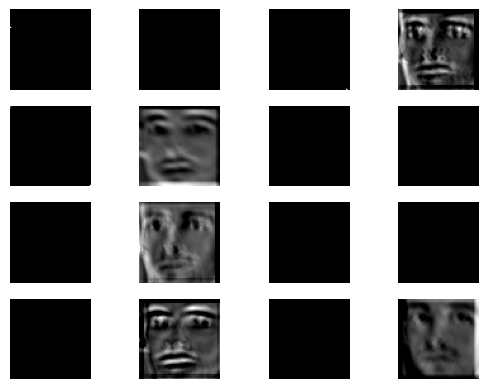

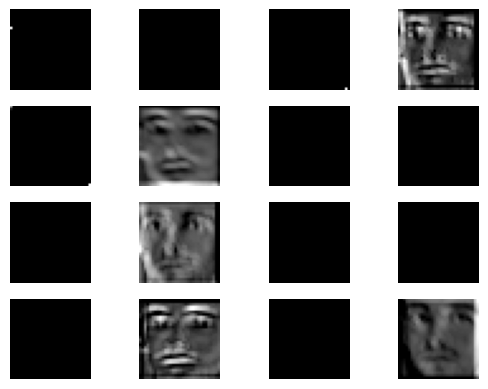

In [16]:
# Feature maps
layer_outputs = [layer.output for layer in model2.layers]
layers_model = keras.Model(inputs=model2.layers[0].input, outputs=layer_outputs )

one_image = X_test[img_index:img_index+1]
outputs = layers_model.predict(one_image)

conv_output = outputs[0]
pooling_output = outputs[1]
print(conv_output.shape)
print(pooling_output.shape)

# For loop
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(conv_output[0, :, :, i], cmap=plt.cm.gray)
    plt.axis("off")
plt.show()

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(pooling_output[0, :, :, i], cmap=plt.cm.gray)
    plt.axis("off")
plt.show()

## Part IV: Model comparison & model optimization


### Step 14: Model comparison

Comment on the differences in the features maps between this model and the previous one. Which network gave better predictions on the test set?

<b>Answers:

##### <u>How do the feature maps differ?</u> 
- Model 1 used a 3-by-3 window and Model 2 used a 9-by-9 window. Model 1’s maps were sharper and mostly active. Model 2’s were smoother, and many filters were solid black on this face. A bigger window looks at a larger neighborhood, so it picks up broad shading instead of fine edges.

##### <u>Which network predicted the test set better?</u>  
Model 1 was about 0.40 loss and 0.93 accuracy. Model 2 was about 0.385 loss and 0.92 accuracy. They are close: Model 2 was slightly better on loss, while Model 1 was slightly better on accuracy.

### Step 15: Model 3- Optimized neural network

Optimize the neural network to improve the accuracy on the test set. You should try to get a better accuracy than both of the previous models.  Consider changing the following, then print the accuracy on the test set:
*   Number of convolutional and pooling layers
*   Number of filters in the convolutional layer
*   Window size
*   Number of fully connected layers and neurons
*   Regularization (L1/L2 penalty, dropout, early stopping)
*   Number of epochs and batch size

Call this model `model3`.

In [21]:
# Convolution Neural Network Model
model3 = Sequential()

model3.add(Conv2D(32, kernel_size=3, activation="relu", padding="same",
                  input_shape=(64, 64, 1)))
model3.add(MaxPooling2D(pool_size=(2, 2), strides=2))

model3.add(Conv2D(64, kernel_size=3, activation="relu", padding="same"))
model3.add(MaxPooling2D(pool_size=(2, 2), strides=2))

model3.add(Flatten())
model3.add(Dense(128, activation="relu"))
model3.add(Dropout(0.5))
model3.add(Dense(40, activation="softmax"))

In [23]:
# Compiling model3
model3.compile(optimizer="adam", 
              loss="categorical_crossentropy", 
              metrics=["accuracy"])
model3.fit(X_train, y_train, epochs=30, batch_size=10, 
          validation_data=(X_test, y_test))

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.0150 - loss: 3.7494 - val_accuracy: 0.0250 - val_loss: 3.6876
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.0100 - loss: 3.6934 - val_accuracy: 0.0250 - val_loss: 3.6886
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.0250 - loss: 3.6896 - val_accuracy: 0.0400 - val_loss: 3.6887
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.0250 - loss: 3.6893 - val_accuracy: 0.0250 - val_loss: 3.6881
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.0400 - loss: 3.6887 - val_accuracy: 0.0300 - val_loss: 3.6884
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.0150 - loss: 3.7076 - val_accuracy: 0.0500 - val_loss: 3.6844
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.0400 - loss: 3.6861 - val_accuracy: 0.1150 - val_loss: 3.6755
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.0550 - loss: 3.6588 - val_accuracy: 0.0250 - v

In [24]:
model3.evaluate(X_test, y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9350 - loss: 0.3387


[0.3387138843536377, 0.9350000023841858]

### Step 16: Reflection on Model 3

Write a few sentences describing how you optimized the model in this part. What worked well?

<b>Answers</b>

I optimized the model by using two conv-pool blocks instead of one, increasing the filters from 16 to 32 and then 64, adding a 128-unit dense layer, and placing dropout of 0.5 before the softmax. I also trained for 30 epochs instead of 20. The extra block lets the network combine features, and dropout keeps it from memorizing the 200 training faces. This worked well: test accuracy rose to 0.935 and loss fell to about 0.34, better than both earlier models.